# Exploring AlphaFold with Python: Human Insulin

**This lab is outside the original scope of the course**

A five-step, hands-on notebook to explore an **AlphaFold-predicted protein structure**, from downloading the file to visualising 3D geometry and prediction confidence.

**Protein:** human insulin precursor (`P01308`, UniProt). **Structure:** AlphaFold prediction, not an experimental measurement. The precursor includes regions that are removed when mature insulin is produced.

### What you will learn
1. Install the required packages.
2. Retrieve the structure from the AlphaFold Protein Structure Database and cache it locally.
3. Explore its shape using an interactive molecular cartoon with `py3Dmol`.
4. Plot alpha-carbon coordinates in 3D with Plotly, coloured by pLDDT.
5. Plot pLDDT by residue with Matplotlib.

**Requirements:** Python 3.10+ recommended, Jupyter Notebook/JupyterLab, internet access for the initial download. Interactive displays may require a notebook frontend that supports HTML and Plotly.

## Step 1. Install the libraries

Run once for the notebook kernel. Restart the kernel if your environment asks you to, then continue. `%pip` installs into the current Jupyter kernel's Python environment.

In [7]:
%pip install biopython plotly py3Dmol requests matplotlib numpy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 2. Download the AlphaFold structure

The API returns metadata for the UniProt accession. We use its `pdbUrl` rather than hard-coding a versioned filename. The PDB file is saved under `data/alphafold/` and **not downloaded again** if already present and non-empty. The structure will be downloaded the first time this cell is run.

**Reference:** [AlphaFold database](https://alphafold.ebi.ac.uk/entry/P01308) · [Prediction API](https://alphafold.ebi.ac.uk/api/prediction/P01308)

In [8]:
from pathlib import Path
import requests

UNIPROT_ID = "P01308"
DATA_DIR = Path("data/alphafold")
DATA_DIR.mkdir(parents=True, exist_ok=True)
PDB_PATH = DATA_DIR / f"{UNIPROT_ID}.pdb"

api_url = f"https://alphafold.ebi.ac.uk/api/prediction/{UNIPROT_ID}"

if PDB_PATH.is_file() and PDB_PATH.stat().st_size > 0:
    print(f"Using cached structure: {PDB_PATH} ({PDB_PATH.stat().st_size:,} bytes)")
else:
    try:
        api_response = requests.get(api_url, timeout=30)
        api_response.raise_for_status()
        predictions = api_response.json()
        if not predictions:
            raise ValueError(f"No AlphaFold predictions found for {UNIPROT_ID}")
        pdb_url = next((p.get("pdbUrl") for p in predictions if p.get("pdbUrl")), None)
        if not pdb_url:
            raise ValueError("The AlphaFold API did not provide a PDB download URL")

        pdb_response = requests.get(pdb_url, timeout=60)
        pdb_response.raise_for_status()
        if not pdb_response.content.strip():
            raise ValueError("Downloaded PDB file is empty")
        PDB_PATH.write_bytes(pdb_response.content)
        print(f"Downloaded structure: {PDB_PATH} ({PDB_PATH.stat().st_size:,} bytes)")
        print("Source:", pdb_url)
    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError(
            "Could not download the structure. Check your internet connection and "
            f"the AlphaFold entry for {UNIPROT_ID}: {api_url}"
        ) from exc

pdb_data = PDB_PATH.read_text(encoding="utf-8")
assert "ATOM" in pdb_data, "This file does not appear to contain atomic coordinates"
print("Ready to explore", UNIPROT_ID)

Using cached structure: data/alphafold/P01308.pdb (72,575 bytes)
Ready to explore P01308


## Step 3. Display an interactive molecular cartoon (`py3Dmol`)

A *cartoon* representation highlights common protein structural elements, including helices and loops. **Spectrum colouring** follows the sequence from one end to the other: it does **not** indicate AlphaFold prediction confidence. Drag to rotate; scroll to zoom.

In [9]:
import py3Dmol

view = py3Dmol.view(width=850, height=550)
view.addModel(pdb_data, "pdb")
view.setStyle({"cartoon": {"color": "spectrum"}})
view.setBackgroundColor("white")
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Optional: show approximate confidence colouring

For an AlphaFold PDB structure, the PDB **B-factor field** stores per-residue **pLDDT confidence** scores. The colour gradient below uses that field. The precise colour mapping may differ from the AlphaFold website's four-colour legend.

| pLDDT | Interpretation |
|---|---|
| > 90 | Very high confidence |
| 70–90 | Confident |
| 50–70 | Low confidence |
| < 50 | Very low confidence |

A low score does not automatically imply that the model is wrong; some protein regions may be flexible or disordered.

In [10]:
confidence_view = py3Dmol.view(width=850, height=550)
confidence_view.addModel(pdb_data, "pdb")
confidence_view.setStyle({
    "cartoon": {
        "colorscheme": {"prop": "b", "gradient": "roygb", "min": 0, "max": 100}
    }
})
confidence_view.setBackgroundColor("white")
confidence_view.zoomTo()
confidence_view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Step 4. Plot the protein backbone with Plotly

A protein contains thousands of atoms. To keep the plot readable, we select just one **alpha-carbon (`CA`)** atom from each amino-acid residue and join them in chain order. These coordinates come from the predicted structure, and the pLDDT is read from the PDB B-factor field.

**Note:** connecting `CA` positions with straight lines is a *simplified backbone trace*, not the full molecule or its chemical bonds.

In [11]:
from Bio.PDB import PDBParser
import numpy as np
import plotly.graph_objects as go

structure = PDBParser(QUIET=True).get_structure(UNIPROT_ID, str(PDB_PATH))
model = next(structure.get_models())
chain = next(model.get_chains())  # One chain for this AlphaFold entry

ca_residues = [residue for residue in chain if "CA" in residue]
if not ca_residues:
    raise ValueError("No alpha-carbon (CA) atoms found in this structure")

ca_atoms = [residue["CA"] for residue in ca_residues]
coordinates = np.array([atom.coord for atom in ca_atoms], dtype=float)
plddt = np.array([atom.bfactor for atom in ca_atoms], dtype=float)
residue_numbers = np.array([residue.id[1] for residue in ca_residues])
residue_names = [residue.resname for residue in ca_residues]

print(f"Chain: {chain.id} | Residues with CA: {len(ca_atoms)}")
print(f"Coordinates shape: {coordinates.shape}; confidence shape: {plddt.shape}")
print(f"Mean pLDDT: {plddt.mean():.1f} | Min: {plddt.min():.1f} | Max: {plddt.max():.1f}")

Chain: A | Residues with CA: 110
Coordinates shape: (110, 3); confidence shape: (110,)
Mean pLDDT: 52.9 | Min: 37.7 | Max: 85.6


In [12]:
hover_labels = [
    f"Residue {num} ({name})<br>pLDDT: {score:.1f}"
    for num, name, score in zip(residue_numbers, residue_names, plddt)
]

fig = go.Figure()
fig.add_trace(go.Scatter3d(
    x=coordinates[:, 0],
    y=coordinates[:, 1],
    z=coordinates[:, 2],
    mode="lines+markers",
    line=dict(color="grey", width=4),
    marker=dict(
        size=4,
        color=plddt,
        colorscale="RdYlBu",  # low = red; high = blue
        cmin=0,
        cmax=100,
        colorbar=dict(title="pLDDT"),
    ),
    text=hover_labels,
    hoverinfo="text",
    name="Alpha-carbon backbone",
))
fig.update_layout(
    title=f"AlphaFold {UNIPROT_ID}: Predicted Backbone and Confidence",
    scene=dict(
        xaxis_title="X (Å)",
        yaxis_title="Y (Å)",
        zaxis_title="Z (Å)",
        aspectmode="data",  # preserve physical proportions
    ),
    width=850,
    height=650,
    margin=dict(l=0, r=0, b=0, t=55),
)
fig.show()

## Step 5. Plot AlphaFold confidence by residue (`Matplotlib`)

The **pLDDT** score is a prediction of *local* confidence from 0 to 100. Plotting it by residue number makes it easier to identify high-confidence segments and potentially flexible or uncertain regions.

**Important:** pLDDT does not describe uncertainty in the relative placement of whole domains; AlphaFold's **Predicted Aligned Error (PAE)** is used for that.

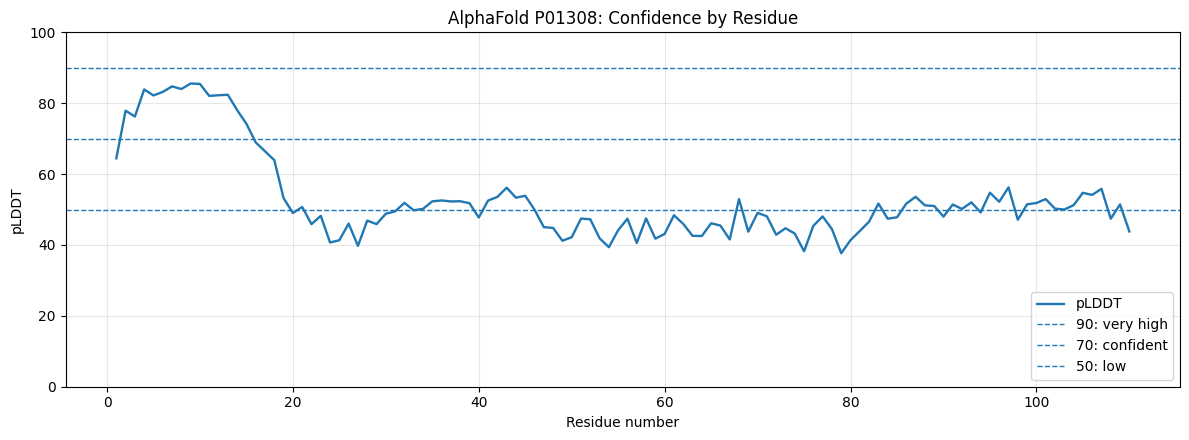

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(residue_numbers, plddt, linewidth=1.7, label="pLDDT")
ax.axhline(90, linestyle="--", linewidth=1, label="90: very high")
ax.axhline(70, linestyle="--", linewidth=1, label="70: confident")
ax.axhline(50, linestyle="--", linewidth=1, label="50: low")
ax.set(
    title=f"AlphaFold {UNIPROT_ID}: Confidence by Residue",
    xlabel="Residue number",
    ylabel="pLDDT",
    ylim=(0, 100),
)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## What to look for

- Compare the **3D shape** with the **confidence-by-residue** plot. Which regions have lower confidence?
- Does the 3D backbone look like a smooth path, or are there abrupt bends?
- Compare `P01308` with another UniProt accession such as human haemoglobin alpha (`P69905`). Change `UNIPROT_ID` in **Step 2**, then rerun the subsequent cells.
- Explore [AlphaFold's P01308 entry](https://alphafold.ebi.ac.uk/entry/P01308) and, if available, its PAE heatmap.

### ML connection
AlphaFold is predicting a **structured 3D output**, not a single class label. The local prediction confidence varies along the output. That's why inspecting uncertainty is as important as visualising the prediction itself.

**Data source:** [AlphaFold Protein Structure Database](https://alphafold.ebi.ac.uk/). Protein coordinates and associated confidence values are those provided by the database for the selected entry.